# 02 — Baseline Track B : premier pipeline complet

**But :** construire une chaîne **de bout en bout** (données → traitement → spectrogramme → CNN → score officiel)
et mesurer un **premier score de référence**. Ce n'est pas le modèle final : chaque amélioration future
sera comparée à ce chiffre, en changeant **une seule chose à la fois**.

Chaque choix vient d'une observation du notebook `01_eda.ipynb` :

| Étape | Choix | Type | Justification (EDA) |
| --- | --- | --- | --- |
| Recadrage | garder 19–122 µs (12 360 échantillons sur 16 800) | data processing | le pulse est toujours entre 20,1 et 120,6 µs (§2) |
| Normalisation | diviser chaque pulse par sa propre puissance (RMS) | data processing | l'amplitude ne doit jamais servir d'indice (§9) |
| Bruit | SNR tiré au hasard parmi les 13, nouveau bruit à chaque époque | data processing / augmentation | bruit officiel, identique au test (§10) |
| Représentation | STFT bilatérale, Hann 256, pas 128, log-puissance, standardisée | **feature engineering** | meilleur compromis temps/fréquence (§7) |
| Modèle | petit CNN + pooling global | modèle | motif de 5 à 50 colonnes, position variable (§6, §8) |
| Déséquilibre | loss pondérée par 1/effectif | entraînement | `cw` 16× plus rare que `fsk` (§1) |
| Évaluation | validation aux 13 SNR, score par classe et par durée | évaluation | confusions `barker`/`cw` et chirps attendues (§5) |

**Limites assumées (machine sans GPU) :** 20 pulses d'entraînement par configuration (sur 80) et 8 époques ;
évaluation sur 4 pulses de validation par configuration (sur 20), soit 34 320 exemples aux 13 SNR.

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from torch.utils.data import DataLoader

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from radarml.constants import CLASSES, REQUESTED_SNRS_DB, SAMPLE_RATE_HZ
from radarml.manifest import load_manifest, select, class_counts
from radarml.noise import degrade_official
from radarml.features import CROP, preprocess
from radarml.data import TrainDataset, EvalDataset
from radarml.models import build_model, count_parameters
from radarml.training import class_weights, train_one_epoch, predict
from radarml.metrics import challenge_report, confusion

DATA = ROOT / "data" / "raw" / "recorded_dataset"
FIG_DIR = ROOT / "reports" / "figures" / "baseline"
MODEL_DIR = ROOT / "models" / "baseline"
for d in (FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SEQ = LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#9cc3ef", BLUE, "#0d3a73"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "lines.linewidth": 2})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight", facecolor="white")

def duration_of(ref):
    # Analyse uniquement (grouper les résultats) - jamais une entrée du modèle.
    return int(ref.file.split("_")[0].removesuffix("us"))

## 1. Configuration de l'expérience

Tous les réglages sont dans **un seul dictionnaire**. Pour une nouvelle expérience : copier le notebook,
changer **une** valeur, relancer, noter le résultat dans `docs/EXPERIMENT_LOG.md`.

In [2]:
CONFIG = dict(
    experiment="E001_baseline",
    seed=42,
    train_pulses_per_file=20,        # sur 80 disponibles
    monitor_pulses_per_file=1,       # suivi pendant l'entraînement (validation)
    val_pulses_per_file=4,           # évaluation finale (validation), sur 20 disponibles
    train_snrs=list(REQUESTED_SNRS_DB),
    stft=dict(n_fft=256, hop_length=128, freq_pool=2),
    cnn=dict(channels=(16, 32, 64, 128), dropout=0.3),
    epochs=8, batch_size=64, lr=2e-3, weight_decay=1e-4, label_smoothing=0.05,
    num_workers=3,
)
torch.manual_seed(CONFIG["seed"]); np.random.seed(CONFIG["seed"])
print(json.dumps(CONFIG, indent=1))

{
 "experiment": "E001_baseline",
 "seed": 42,
 "train_pulses_per_file": 20,
 "monitor_pulses_per_file": 1,
 "val_pulses_per_file": 4,
 "train_snrs": [
  30,
  25,
  20,
  15,
  10,
  5,
  0,
  -5,
  -10,
  -15,
  -20,
  -25,
  -30
 ],
 "stft": {
  "n_fft": 256,
  "hop_length": 128,
  "freq_pool": 2
 },
 "cnn": {
  "channels": [
   16,
   32,
   64,
   128
  ],
  "dropout": 0.3
 },
 "epochs": 8,
 "batch_size": 64,
 "lr": 0.002,
 "weight_decay": 0.0001,
 "label_smoothing": 0.05,
 "num_workers": 3
}


## 2. Sélection des données

**Ce qu'on fait :** on prend les N premiers pulses de chaque configuration dans le split officiel.
Règle de sélection fixe et documentée (demandé par les organisateurs). Aucun pulse de validation à l'entraînement.

In [3]:
refs = load_manifest(DATA, ROOT / "data" / "manifest" / "split_manifest.csv")
train_refs = select(refs, "train", CONFIG["train_pulses_per_file"])
monitor_refs = select(refs, "validation", CONFIG["monitor_pulses_per_file"])
val_refs = select(refs, "validation", CONFIG["val_pulses_per_file"])
assert not {(r.file, r.pulse_index) for r in train_refs} & {(r.file, r.pulse_index) for r in val_refs}

counts = pd.DataFrame({"train (pulses)": class_counts(train_refs), "validation (pulses)": class_counts(val_refs)})
counts["poids de la loss"] = class_weights(train_refs).numpy().round(2)
display(counts)
print(f"Entraînement : {len(train_refs):,} pulses (SNR aléatoire à chaque époque)")
print(f"Évaluation   : {len(val_refs):,} pulses × 13 SNR = {len(val_refs) * 13:,} exemples")

,train (pulses),validation (pulses),poids de la loss
barker,1440,288,1.31
cw,240,48,7.86
fmcw,1920,384,0.98
fsk,3840,768,0.49
hyp,1920,384,0.98
nlfm,1920,384,0.98
quad,1920,384,0.98


Entraînement : 13,200 pulses (SNR aléatoire à chaque époque)
Évaluation   : 2,640 pulses × 13 SNR = 34,320 exemples


**Lecture :** le poids de `cw` (~2,2) est 16 fois celui de `fsk` (~0,14) : une erreur sur un `cw` coûte autant
dans la loss que 16 erreurs sur des `fsk`. C'est ce qui aligne l'entraînement sur la *balanced accuracy*.

## 3. Le traitement d'un pulse, étape par étape

**Ce qu'on montre :** ce que devient un pulse avant d'entrer dans le réseau.
1. **Brut** : 16 800 échantillons I/Q (140 µs), avec bruit ajouté au SNR demandé.
2. **Data processing** : recadrage 19–122 µs, puis division par le RMS du pulse.
3. **Feature engineering** : STFT → image temps × fréquence (128 × 95), log-puissance standardisée.
   C'est **exactement** l'image que voit le CNN : le calcul est fait par la première couche (fixe) du modèle.

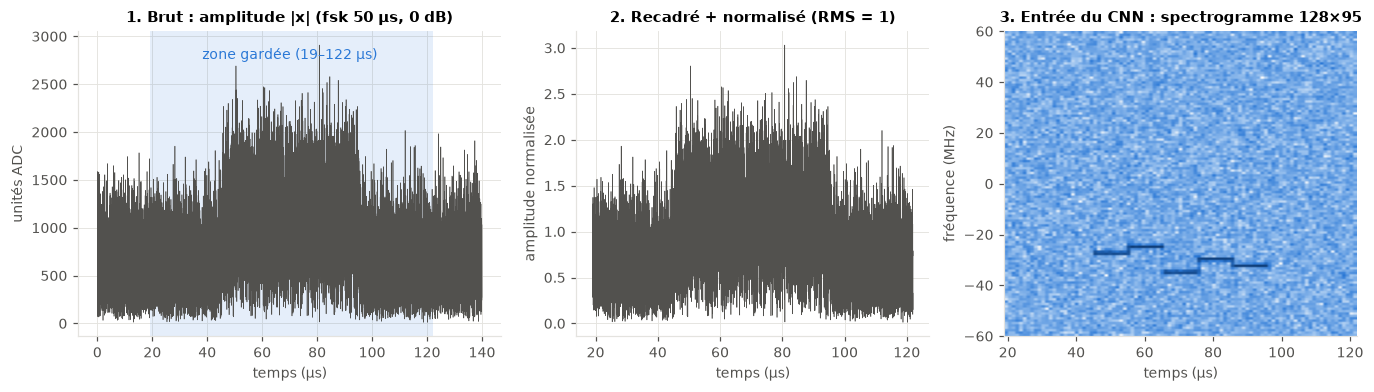

In [4]:
model = build_model(CONFIG["stft"], CONFIG["cnn"])
example = next(r for r in train_refs if r.label == "fsk" and duration_of(r) == 50)
raw = degrade_official(np.load(DATA / example.file, mmap_mode="r")[0, example.pulse_index],
                       example.source_file, 0, example.pulse_index)
iq_raw = raw[0::2].astype(float) + 1j * raw[1::2].astype(float)
x = preprocess(raw)
with torch.no_grad():
    image = model.frontend(torch.from_numpy(x)[None])[0, 0].numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1.2, 1, 1]})
t = np.arange(iq_raw.size) / SAMPLE_RATE_HZ * 1e6
axes[0].plot(t, np.abs(iq_raw), color=INK2, lw=0.4)
axes[0].axvspan(t[CROP.start], t[CROP.stop - 1], color=BLUE, alpha=0.12, lw=0)
axes[0].text(70, np.abs(iq_raw).max() * 0.95, "zone gardée (19–122 µs)", color=BLUE, ha="center")
axes[0].set(title="1. Brut : amplitude |x| (fsk 50 µs, 0 dB)", xlabel="temps (µs)", ylabel="unités ADC")
tc = t[CROP]
axes[1].plot(tc, np.hypot(x[0], x[1]), color=INK2, lw=0.4)
axes[1].set(title="2. Recadré + normalisé (RMS = 1)", xlabel="temps (µs)", ylabel="amplitude normalisée")
axes[2].imshow(image, aspect="auto", origin="lower", cmap=SEQ,
               extent=[tc[0], tc[-1], -SAMPLE_RATE_HZ / 2e6, SAMPLE_RATE_HZ / 2e6])
axes[2].set(title=f"3. Entrée du CNN : spectrogramme {image.shape[0]}×{image.shape[1]}",
            xlabel="temps (µs)", ylabel="fréquence (MHz)"); axes[2].grid(False)
save(fig, "01_processing_steps"); plt.show()

## 4. Le modèle

**Architecture :** STFT fixe (non apprise) → 4 blocs convolutifs (16 → 32 → 64 → 128 filtres, chacun suivi d'une
réduction ×2 de l'image) → **moyenne globale** sur toute l'image → couche de décision à 7 sorties.
La moyenne globale rend le modèle insensible à **l'endroit** où se trouve le motif sur l'image.
Le modèle est entraîné **depuis zéro** (aucun poids pré-entraîné, règle de l'événement).

In [5]:
n_params = count_parameters(model)
print(f"Paramètres entraînables : {n_params:,}  (~{n_params * 4 / 1e6:.1f} Mo en float32)")
print(f"Image d'entrée du CNN : {model.frontend.output_shape()} (fréquence × temps)")
print(model.backbone)

Paramètres entraînables : 292,279  (~1.2 Mo en float32)
Image d'entrée du CNN : (128, 95) (fréquence × temps)
SpecCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, di

## 5. Entraînement

**Ce qui se passe à chaque époque :** chaque pulse d'entraînement est vu une fois, à un SNR tiré au hasard
parmi les 13, avec un bruit neuf (augmentation gratuite). Optimiseur AdamW, taux d'apprentissage en « one-cycle ».
À la fin de chaque époque, on mesure le score officiel sur un petit jeu de **validation** (1 pulse par configuration × 13 SNR)
et on garde la **meilleure époque**.

In [6]:
torch.manual_seed(CONFIG["seed"])
train_ds = TrainDataset(train_refs, DATA, CONFIG["train_snrs"], seed=CONFIG["seed"])
loader_kw = dict(num_workers=CONFIG["num_workers"], persistent_workers=False)
train_loader = DataLoader(train_ds, batch_size=CONFIG["batch_size"], shuffle=True, drop_last=True,
                          generator=torch.Generator().manual_seed(CONFIG["seed"]), **loader_kw)
monitor_loader = DataLoader(EvalDataset(monitor_refs, DATA), batch_size=256, **loader_kw)

criterion = torch.nn.CrossEntropyLoss(weight=class_weights(train_refs), label_smoothing=CONFIG["label_smoothing"])
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=CONFIG["lr"],
                                                total_steps=CONFIG["epochs"] * len(train_loader))
history, best_score, started = [], -1.0, time.perf_counter()
for epoch in range(1, CONFIG["epochs"] + 1):
    train_ds.set_epoch(epoch)
    stats = train_one_epoch(model, train_loader, optimizer, criterion, scheduler)
    out = predict(model, monitor_loader)
    score = challenge_report(out["y_true"], out["y_pred"], out["snr"])["mean_balanced_accuracy"]
    history.append(dict(epoch=epoch, train_loss=stats["loss"], train_acc=stats["accuracy"],
                        val_monitor_bal_acc=score, minutes=stats["seconds"] / 60))
    if score > best_score:
        best_score = score
        torch.save({"config": CONFIG, "state_dict": model.state_dict(), "epoch": epoch}, MODEL_DIR / "model.pt")
    print(f"époque {epoch}/{CONFIG['epochs']} | loss {stats['loss']:.3f} | acc train {stats['accuracy']:.3f} | "
          f"balanced acc validation {score:.4f} | {stats['seconds'] / 60:.1f} min", flush=True)
training_minutes = (time.perf_counter() - started) / 60
history = pd.DataFrame(history)
print(f"Entraînement : {training_minutes:.1f} min | meilleure époque : {int(history.val_monitor_bal_acc.idxmax()) + 1}")

époque 1/8 | loss 1.819 | acc train 0.272 | balanced acc validation 0.3803 | 4.0 min


époque 2/8 | loss 1.404 | acc train 0.550 | balanced acc validation 0.5195 | 3.6 min


époque 3/8 | loss 1.077 | acc train 0.724 | balanced acc validation 0.7256 | 3.5 min


époque 4/8 | loss 0.913 | acc train 0.791 | balanced acc validation 0.7361 | 3.4 min


époque 5/8 | loss 0.860 | acc train 0.809 | balanced acc validation 0.7865 | 3.5 min


époque 6/8 | loss 0.834 | acc train 0.814 | balanced acc validation 0.8094 | 3.5 min


époque 7/8 | loss 0.806 | acc train 0.825 | balanced acc validation 0.8272 | 4.0 min


époque 8/8 | loss 0.782 | acc train 0.838 | balanced acc validation 0.8284 | 4.7 min


Entraînement : 40.2 min | meilleure époque : 8


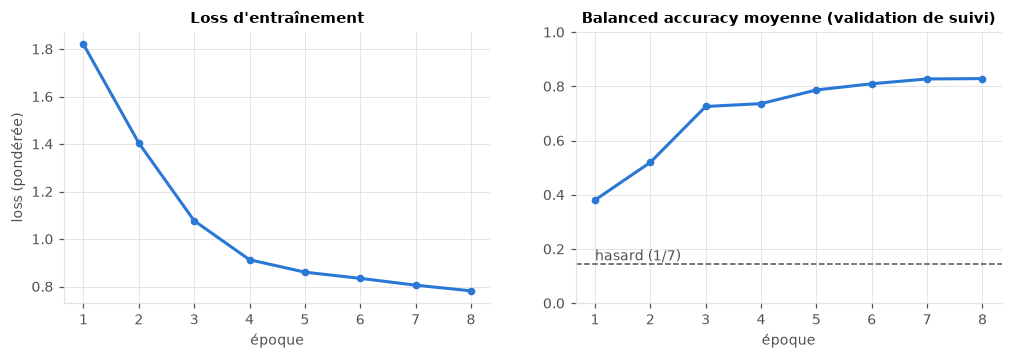

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(history.epoch, history.train_loss, color=BLUE, marker="o", ms=4)
axes[0].set(title="Loss d'entraînement", xlabel="époque", ylabel="loss (pondérée)")
axes[1].plot(history.epoch, history.val_monitor_bal_acc, color=BLUE, marker="o", ms=4)
axes[1].axhline(1 / 7, color=INK2, lw=1, ls="--"); axes[1].text(1, 1 / 7 + 0.015, "hasard (1/7)", color=INK2)
axes[1].set(title="Balanced accuracy moyenne (validation de suivi)", xlabel="époque", ylim=(0, 1))
save(fig, "02_training_curves"); plt.show()

## 6. Évaluation complète sur la validation

**Ce qu'on fait :** on recharge la meilleure époque et on prédit les 34 320 exemples de validation
(4 pulses × 660 configurations × 13 SNR), avec le bruit officiel. Le score est calculé **comme le correcteur officiel**.

In [8]:
checkpoint = torch.load(MODEL_DIR / "model.pt", weights_only=False)
model.load_state_dict(checkpoint["state_dict"])
val_loader = DataLoader(EvalDataset(val_refs, DATA), batch_size=256, **loader_kw)
started = time.perf_counter()
out = predict(model, val_loader)
eval_minutes = (time.perf_counter() - started) / 60
report = challenge_report(out["y_true"], out["y_pred"], out["snr"])
per_snr = pd.DataFrame(report["per_snr"]).set_index("requested_snr_db")[["balanced_accuracy", "accuracy"]]
print(f"SCORE (moyenne balanced accuracy, 13 SNR) : {report['mean_balanced_accuracy']:.4f}")
print(f"Tie-break (-20/-25/-30 dB)                : {report['tiebreak_low_snr']:.4f}")
print(f"Époque retenue : {checkpoint['epoch']} | évaluation : {eval_minutes:.1f} min")
display(per_snr.round(3).T)

SCORE (moyenne balanced accuracy, 13 SNR) : 0.8298
Tie-break (-20/-25/-30 dB)                : 0.3188
Époque retenue : 8 | évaluation : 4.5 min


requested_snr_db,30,25,20,15,10,5,0,-5,-10,-15,-20,-25,-30
balanced_accuracy,1.0,1.0,1.0,1.0,1.0,1.0,0.989,0.975,0.960,0.906,0.591,0.221,0.144
accuracy,1.0,1.0,1.0,1.0,1.0,1.0,0.991,0.980,0.975,0.954,0.611,0.187,0.129


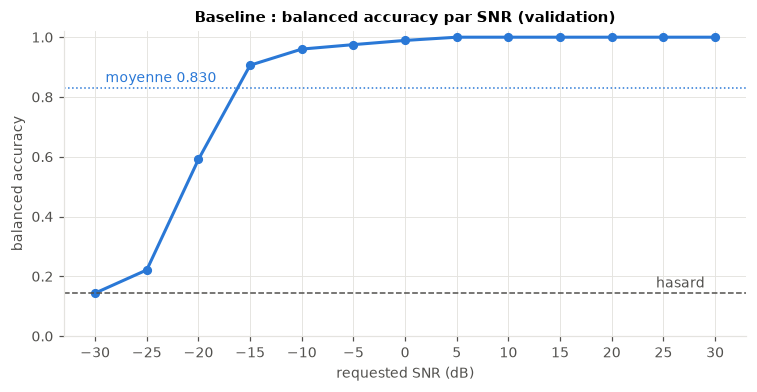

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(per_snr.index, per_snr.balanced_accuracy, color=BLUE, marker="o", ms=5)
ax.axhline(1 / 7, color=INK2, lw=1, ls="--"); ax.text(29, 1 / 7 + 0.02, "hasard", color=INK2, ha="right")
ax.axhline(report["mean_balanced_accuracy"], color=BLUE, lw=1, ls=":")
ax.text(-29, report["mean_balanced_accuracy"] + 0.02, f"moyenne {report['mean_balanced_accuracy']:.3f}", color=BLUE)
ax.set(xlabel="requested SNR (dB)", ylabel="balanced accuracy", ylim=(0, 1.02), xticks=list(REQUESTED_SNRS_DB),
       title="Baseline : balanced accuracy par SNR (validation)")
save(fig, "03_balanced_accuracy_vs_snr"); plt.show()

## 7. Quelles classes posent problème ?

**Rappel par classe et par SNR** (part des exemples de la classe correctement reconnus). Plus c'est foncé, mieux c'est.

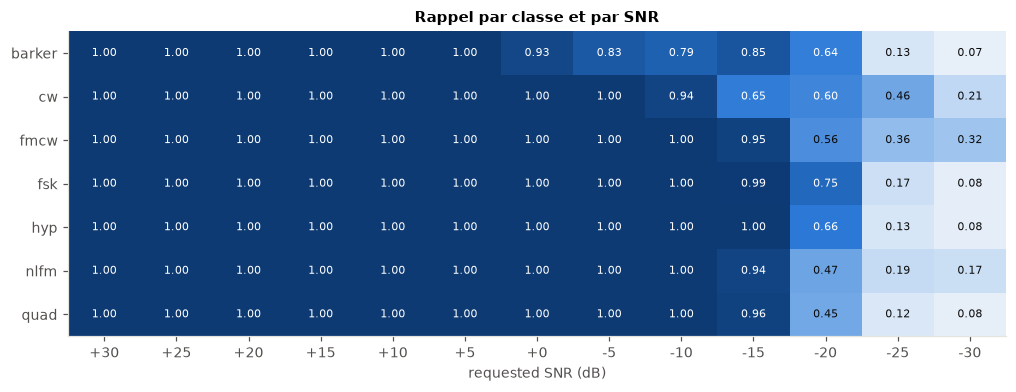

In [10]:
recall = pd.DataFrame({snr: np.diag(np.array(r["confusion_matrix"])) / np.array(r["confusion_matrix"]).sum(1)
                       for snr, r in zip(per_snr.index, report["per_snr"])}, index=CLASSES)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.imshow(recall.values, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
for i in range(recall.shape[0]):
    for j in range(recall.shape[1]):
        v = recall.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if v > 0.6 else INK)
ax.set_xticks(range(recall.shape[1]), [f"{s:+d}" for s in recall.columns]); ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set(xlabel="requested SNR (dB)", title="Rappel par classe et par SNR"); ax.grid(False)
save(fig, "04_recall_class_snr"); plt.show()

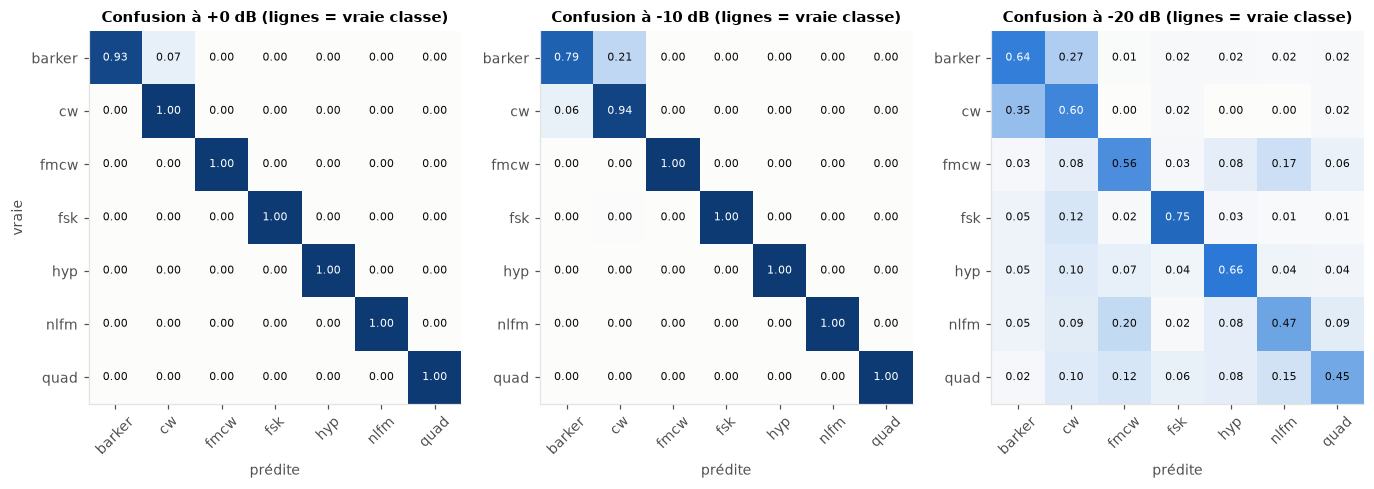

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, snr in zip(axes, (0, -10, -20)):
    m = np.array(next(r for r in report["per_snr"] if r["requested_snr_db"] == snr)["confusion_matrix"], float)
    m = m / m.sum(1, keepdims=True)
    ax.imshow(m, cmap=SEQ, vmin=0, vmax=1)
    for i in range(7):
        for j in range(7):
            ax.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if m[i, j] > 0.6 else INK)
    ax.set_xticks(range(7), CLASSES, rotation=45); ax.set_yticks(range(7), CLASSES)
    ax.set(title=f"Confusion à {snr:+d} dB (lignes = vraie classe)", xlabel="prédite"); ax.grid(False)
axes[0].set_ylabel("vraie")
save(fig, "05_confusion"); plt.show()

## 8. Effet de la durée du pulse

**Ce qu'on vérifie :** la section 3 de l'EDA prévoyait que les pulses courts (SNR réel plus haut mais moins de colonnes)
et longs ont des difficultés différentes. On recalcule la balanced accuracy séparément pour 10, 50 et 100 µs.

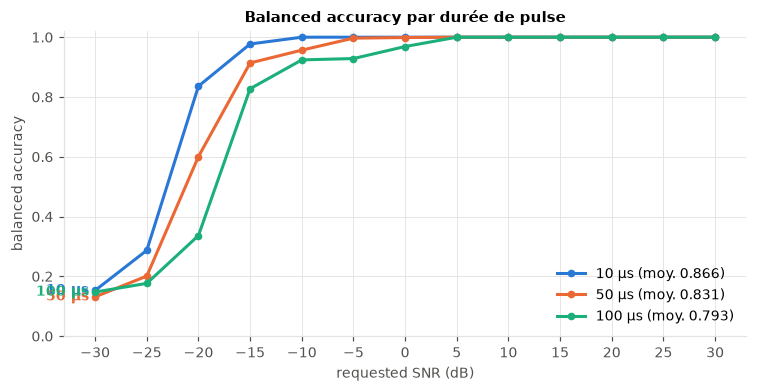

In [12]:
durations = np.array([duration_of(val_refs[i]) for i in out["ref_index"]])
fig, ax = plt.subplots(figsize=(8, 3.6))
by_duration = {}
for d, color in zip((10, 50, 100), (BLUE, ORANGE, AQUA)):
    mask = durations == d
    rep = challenge_report(out["y_true"][mask], out["y_pred"][mask], out["snr"][mask])
    by_duration[d] = rep["mean_balanced_accuracy"]
    xs = [r["requested_snr_db"] for r in rep["per_snr"]]; ys = [r["balanced_accuracy"] for r in rep["per_snr"]]
    ax.plot(xs, ys, color=color, marker="o", ms=4, label=f"{d} µs (moy. {rep['mean_balanced_accuracy']:.3f})")
    ax.text(xs[-1] - 0.6, ys[-1], f"{d} µs", color=color, ha="right", va="center", fontweight="bold")
ax.legend(loc="lower right", frameon=False)
ax.set(xlabel="requested SNR (dB)", ylabel="balanced accuracy", ylim=(0, 1.02), xticks=list(REQUESTED_SNRS_DB),
       title="Balanced accuracy par durée de pulse")
save(fig, "06_by_duration"); plt.show()

## 9. Coût : temps et taille

Le règlement demande le **temps d'inférence par pulse en incluant le calcul du spectrogramme**.

In [13]:
model.eval()
batch = torch.from_numpy(np.stack([preprocess(np.load(DATA / r.file, mmap_mode="r")[0, r.pulse_index])
                                   for r in val_refs[:256]]))
with torch.inference_mode():
    model(batch[:32])
    t0 = time.perf_counter(); model(batch); model_ms = (time.perf_counter() - t0) / len(batch) * 1e3
    t0 = time.perf_counter(); model.frontend(batch); stft_ms = (time.perf_counter() - t0) / len(batch) * 1e3
costs = {"paramètres": n_params, "taille modèle (Mo)": round((MODEL_DIR / "model.pt").stat().st_size / 1e6, 2),
         "inférence (ms/pulse, STFT incluse)": round(model_ms, 2), "dont STFT (ms/pulse)": round(stft_ms, 2),
         "entraînement (min)": round(training_minutes, 1), "matériel": f"CPU, {torch.get_num_threads()} threads, pas de GPU"}
display(pd.Series(costs, name="valeur").to_frame())

,valeur
paramètres,292279
taille modèle (Mo),1.19
"inférence (ms/pulse, STFT incluse)",5.1
dont STFT (ms/pulse),0.46
entraînement (min),40.2
matériel,"CPU, 4 threads, pas de GPU"


In [14]:
summary = dict(experiment=CONFIG["experiment"], config=CONFIG, best_epoch=checkpoint["epoch"],
               mean_balanced_accuracy=report["mean_balanced_accuracy"], tiebreak_low_snr=report["tiebreak_low_snr"],
               by_duration=by_duration, costs=costs, per_snr=report["per_snr"], history=history.to_dict("records"))
(ROOT / "reports" / "baseline").mkdir(parents=True, exist_ok=True)
(ROOT / "reports" / "baseline" / "validation_report.json").write_text(json.dumps(summary, indent=1, default=str))
print("Rapport : reports/baseline/validation_report.json | modèle : models/baseline/model.pt (non versionné)")

Rapport : reports/baseline/validation_report.json | modèle : models/baseline/model.pt (non versionné)


## 10. Conclusions

**Score de validation : 0,830** (moyenne de la balanced accuracy sur les 13 SNR) · tie-break (−20/−25/−30 dB) : **0,319** · hasard : 0,143.

| Constat | Détail | Lien avec l'EDA |
| --- | --- | --- |
| ✅ SNR ≥ +5 dB : **parfait** (1,000) | 9 SNR sur 13 sont déjà à ≥ 0,96 jusqu'à −10 dB | — |
| ⚠️ La chute est entre −15 et −25 dB | 0,906 (−15) → 0,591 (−20) → 0,221 (−25) → 0,144 (−30, hasard) | — |
| ⚠️ Confusion n°1 : `barker` ↔ `cw` | dès 0 dB (7 % des barker → cw), 21 % à −10 dB, 27–35 % dans les deux sens à −20 dB | prévue en §5 ✅ |
| ⚠️ Confusion n°2 : chirps entre eux | à −20 dB : nlfm → fmcw 20 %, fmcw → nlfm 17 %, quad → nlfm 15 % | prévue en §5 ✅ |
| 🔎 Les pulses **longs** sont les plus difficiles | moyenne 0,866 (10 µs) > 0,831 (50 µs) > 0,793 (100 µs) ; à −20 dB : 0,84 vs 0,34 | SNR réel plus haut dans les pulses courts (§3) ✅ |
| 🔎 Modèle sous-entraîné | le score monte encore à la dernière époque ; seulement 20 pulses / config sur 80 | — |
| Coût | 292 k paramètres, 1,2 Mo, **5,1 ms/pulse** (dont STFT 0,5 ms), 40 min d'entraînement sur CPU | — |

**Où sont les points à gagner :** les 9 SNR de +30 à −10 dB sont quasi saturés. Toute la marge est dans **−15 à −30 dB**
(chaque SNR vaut 1/13 = 0,077 du score), qui sert aussi au tie-break.

**Ce que ça suggère :** un pulse long et faible étale son énergie sur beaucoup de colonnes du spectrogramme et le CNN
ne l'accumule pas assez. Une fenêtre STFT **plus longue** concentre l'énergie d'une trace étroite (gain de traitement)
→ c'est l'argument principal pour tester le **multi-résolution** (ajouter une fenêtre de 1024). Pour `barker`/`cw`,
la seule différence est la présence de sauts de phase → garder une **fenêtre courte** et la pleine résolution.

**Expériences suivantes (une variable à la fois, comparer à 0,830) :** voir `docs/EXPERIMENT_LOG.md`.